# RutaPro · Notebook 02: Modelamiento y ajuste de hiperparámetros

**Fase 4 del trabajo.** Se implementan un modelo de referencia y tres algoritmos de familias distintas, y se ajustan sus hiperparámetros **solo con el conjunto de validación**. El conjunto de prueba no se toca en este notebook: se usa una única vez en el notebook 03 para la comparación final.

| # | Modelo | Familia | Rol |
|---|---|---|---|
| 0 | Popularidad | No personalizado | Baseline |
| 1 | TF-IDF + similitud del coseno | Basado en contenido | Algoritmo 1 |
| 2 | KNN (usuario e ítem) | Colaborativo por vecinos | Algoritmo 2 |
| 3 | LightFM (WARP/BPR) con atributos | Factorización híbrida | Algoritmo 3 · **innovación** (no visto en clase) |

**Protocolo de ajuste** (definido en el notebook 01):
- Entrenamiento: pares de la partición `train` (esquema temporal por usuario).
- Validación: inscripciones de la partición `valid` de los 133 estudiantes elegibles.
- Regla común: no se recomiendan cursos en los que el estudiante ya se inscribió en entrenamiento.
- Criterio de selección: **NDCG@10** (premia acertar y además ubicar el acierto arriba); Hit Rate@10 como criterio secundario.
- **Regla de parsimonia:** con 133 estudiantes y una inscripción por estudiante, diferencias pequeñas de NDCG son ruido. Entre las configuraciones a menos de **0.01** del mejor NDCG@10 se elige la más simple (menos vecinos, menos factores, menos épocas o menor peso del perfil declarado).

El código de los modelos está en `rutapro_rec.py` (misma carpeta) para que el notebook 03 y la aplicación usen exactamente las mismas implementaciones. Abajo se muestra el código de cada modelo antes de ajustarlo.

In [ ]:
import os, sys, subprocess
from google.colab import drive

NECESITA_LIGHTFM = True

# 1) Conectar el Drive y entrar a la carpeta del proyecto
drive.mount('/content/drive')
PROY = "/content/drive/MyDrive/RutaPro"
os.chdir(PROY + "/02_Notebooks")
print("Carpeta actual:", os.getcwd())

# 2) Comprobar que están los archivos imprescindibles
faltan = [f for f in ["rutapro_rec.py", "rutapro_sim.py", "rutapro_extra.py", "rutapro_mooc.py",
                      "resultados/hiperparametros.json", "../01_Datos/cursos.csv",
                      "../01_Datos/pares_usuario_curso.csv"] if not os.path.exists(f)]
print("Archivos que faltan:", faltan if faltan else "ninguno, todo en su sitio")

# 3) LightFM: usa la copia compilada en el Drive; si no existe, la compila (≈ 2 min) y la guarda
def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-1500:], r.stderr[-1500:])
        raise RuntimeError("Falló: " + cmd[:70])

if NECESITA_LIGHTFM:
    LF = PROY + "/lightfm_src"
    if not os.path.exists(LF + "/lightfm"):
        print("Compilando LightFM, un momento...")
        sh("pip install -q cython")
        sh("rm -rf /content/lightfm_src && git clone -q --depth 1 https://github.com/lyst/lightfm.git /content/lightfm_src")
        p = "/content/lightfm_src/setup.py"
        s = open(p).read()
        s = s.replace("compiler_directives={'language_level' : \"3\"}",
                      "compiler_directives={'language_level': \"3\", 'legacy_implicit_noexcept': True}").replace("-march=native", "-O2")
        open(p, "w").write(s)
        sh("cd /content/lightfm_src && python setup.py cythonize -q && python setup.py build_ext --inplace -q")
        sh("rm -rf '" + LF + "' && cp -r /content/lightfm_src '" + LF + "'")
    sys.path.insert(0, LF)
    import lightfm
    print("LightFM", lightfm.__version__)

In [ ]:
import json, inspect, time, warnings
TOL = 0.01
def elegir(grid, orden):
    # Regla de parsimonia: dentro de TOL del mejor NDCG@10, la configuración más simple según `orden`
    cand = grid[grid.ndcg >= grid.ndcg.max() - TOL]
    return cand.sort_values(orden).iloc[0]
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings("ignore")

import rutapro_rec as rr

AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9890"
TXT, TXT2 = "#0b0b0b", "#52514e"
mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d4d3cd", "axes.labelcolor": TXT2, "xtick.color": TXT2, "ytick.color": TXT2,
    "text.color": TXT, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
    "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110,
})
BASE = rr.ruta_base()
FIG = BASE / "04_Informe" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
RES = BASE / "02_Notebooks" / "resultados"; RES.mkdir(exist_ok=True)
def guardar(fig, n): fig.savefig(FIG / f"{n}.png", dpi=160, bbox_inches="tight")

cursos, usuarios, pares = rr.cargar_datos()
val = rr.construir_particion(cursos, usuarios, pares, etapa="validacion")
print(f"Pares de entrenamiento: {len(val.train)} ({val.train.positivo.sum()} positivos)")
print(f"Inscripciones a predecir en validación: {len(val.evaluar)} | estudiantes elegibles: {len(val.usuarios_elegibles())}")

Pares de entrenamiento: 1235 (658 positivos)
Inscripciones a predecir en validación: 134 | estudiantes elegibles: 133


### Métricas
Para cada estudiante elegible se genera un Top-K y se compara con sus inscripciones de validación:

- **Precision@K** = aciertos / K
- **Recall@K** = aciertos / inscripciones relevantes del estudiante
- **Hit Rate@K** = 1 si hay al menos un acierto en el Top-K
- **NDCG@K** = DCG / IDCG, con $DCG = \sum_{r=1}^{K} \frac{rel_r}{\log_2(r+1)}$ (relevancia binaria)
- **Cobertura** (complementaria) = % del catálogo que aparece en algún Top-K; mide si el sistema solo repite los mismos cursos.

En validación cada estudiante tiene 1 inscripción a predecir, por lo que Recall@K = Hit Rate@K y Precision@K ≤ 1/K.

In [ ]:
print(inspect.getsource(rr.metricas_usuario)); print(inspect.getsource(rr.recomendar))

def metricas_usuario(ranking, relevantes, k):
    top = list(ranking[:k])
    hits = [1 if i in relevantes else 0 for i in top]
    n_hit = sum(hits)
    dcg = sum(h / np.log2(r + 2) for r, h in enumerate(hits))
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(relevantes), k)))
    return {"precision": n_hit / k, "recall": n_hit / len(relevantes),
            "hit_rate": float(n_hit > 0), "ndcg": dcg / idcg if idcg > 0 else 0.0}

def recomendar(modelo, datos: Particion, user_id, n=10, excluir_vistos=True):
    s = np.asarray(modelo.puntajes(user_id), dtype=float).copy()
    if excluir_vistos:
        s[datos.vistos(user_id)] = -np.inf
    # desempate determinista por índice del curso
    return np.lexsort((np.arange(len(s)), -s))[:n]



## 0. Baseline: Popularidad

- **Principio:** recomienda a todos los cursos con más inscripciones en el periodo de entrenamiento (sin personalización).
- **Datos de entrada:** solo las inscripciones de entrenamiento (nunca las de validación o prueba, para evitar fuga). Desempate: percentil de reseñas del curso en su plataforma.
- **Hiperparámetros:** ninguno.
- **Limitaciones:** todos reciben la misma lista (salvo los cursos ya tomados), lo que refuerza la cola larga y no atiende objetivos poco frecuentes como Project Analyst.

In [ ]:
print(inspect.getsource(rr.Popularidad))
pop = rr.Popularidad().fit(val)
res_val = {"Popularidad": rr.evaluar(pop, val)}
res_val["Popularidad"].round(3)

class Popularidad:
    """Baseline: ordena los cursos por número de inscripciones en entrenamiento."""
    nombre = "Popularidad"

    def fit(self, datos: Particion):
        self.datos = datos
        m = datos.matriz(solo_positivos=True, usar_peso=False)
        conteo = np.asarray(m.sum(axis=0)).ravel()
        # desempate: popularidad relativa en la plataforma de origen (percentil de reseñas)
        pct = datos.cursos.groupby("plataforma")["n_resenas"].rank(pct=True).values
        self._s = conteo + 0.01 * pct
        return self

    def puntajes(self, user_id):
        return self._s



,precision,recall,hit_rate,ndcg,cobertura,usuarios
K,,,,,,
5,0.030,0.150,0.150,0.101,0.103,133
10,0.023,0.233,0.233,0.128,0.168,133


## 1. Filtrado basado en contenido: TF-IDF + similitud del coseno

- **Principio:** recomienda cursos parecidos a los que el estudiante ya tomó. Cada curso se convierte en un vector TF-IDF y el perfil del estudiante es el promedio de los vectores de su historial, ponderado por la intensidad de la interacción (inscripción 3, finalización 4).
- **Datos de entrada:** título, habilidades o temario, categoría, nivel e idioma del curso. Para unir textos en inglés (Coursera) y en español (Platzi, DataCamp, edX), cada categoría añade **términos bilingües** comunes (p. ej. `estadistica statistics probabilidad probability`).
- **Perfil declarado:** el perfil por historial se puede mezclar con el texto del objetivo laboral y los intereses del estudiante, con peso $\alpha$. Con $\alpha = 0$ es contenido puro.
- **Hiperparámetros ajustados:** $\alpha$ (0 a 1; con $\alpha = 1$ solo se usa el perfil declarado), n-gramas (1 o 1-2) y si se incluyen vistas/favoritos en el perfil.
- **Limitaciones:** tiende a recomendar "más de lo mismo" (poca serendipia), depende de la calidad del texto y no aprende de lo que hacen otros estudiantes.

In [ ]:
print(inspect.getsource(rr.ContenidoTFIDF))
print("Ejemplo de texto de un curso:\n", rr.texto_curso(cursos.iloc[0]))

class ContenidoTFIDF:
    """
    Filtrado basado en contenido.
    - Cada curso se representa con TF-IDF de su título, habilidades, términos de categoría, nivel e idioma.
    - El perfil del estudiante es el promedio ponderado (por peso implícito) de los cursos de su historial,
      mezclado con el texto de su perfil declarado (objetivo + intereses) con peso `alpha_perfil`.
    - Puntaje = similitud del coseno entre perfil y curso.
    """
    nombre = "Contenido (TF-IDF)"

    def __init__(self, ngram=(1, 2), min_df=1, usar_vistas=False, alpha_perfil=0.0, sublinear=True):
        self.ngram, self.min_df, self.usar_vistas = ngram, min_df, usar_vistas
        self.alpha_perfil, self.sublinear = alpha_perfil, sublinear

    def fit(self, datos: Particion):
        self.datos = datos
        self.vec = TfidfVectorizer(ngram_range=self.ngram, min_df=self.min_df, sublinear_tf=self.sublinear,
                                   token_pattern=r"(?u)\b\w+\b")
        self.X = normalize(self.v

,alpha_perfil,ngram,usar_vistas,ndcg,hit_rate,cobertura
25,1.0,"(1, 1)",True,0.149,0.293,0.841
24,1.0,"(1, 1)",False,0.149,0.293,0.841
20,0.9,"(1, 1)",False,0.143,0.286,0.869
21,0.9,"(1, 1)",True,0.140,0.278,0.879
13,0.5,"(1, 1)",True,0.138,0.323,0.963
15,0.5,"(1, 2)",True,0.137,0.301,0.953
22,0.9,"(1, 2)",False,0.136,0.293,0.869
18,0.7,"(1, 2)",False,0.135,0.278,0.925


Elegido (parsimonia):
alpha_perfil         0.9
ngram             (1, 1)
usar_vistas        False
ndcg            0.142772
hit_rate        0.285714
cobertura       0.869159


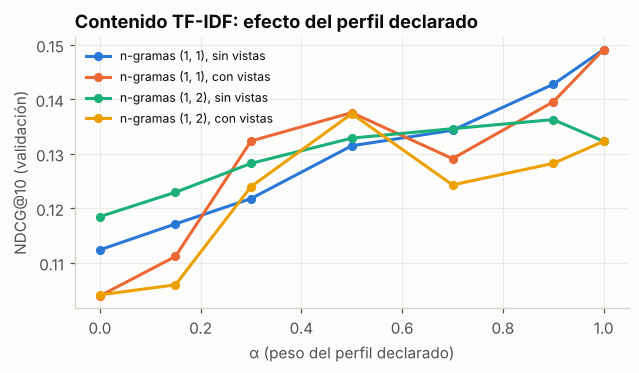

In [ ]:
filas = []
for alpha in [0.0, 0.15, 0.3, 0.5, 0.7, 0.9, 1.0]:
    for ngram in [(1, 1), (1, 2)]:
        for vistas in [False, True]:
            m = rr.ContenidoTFIDF(ngram=ngram, alpha_perfil=alpha, usar_vistas=vistas).fit(val)
            r = rr.evaluar(m, val).loc[10]
            filas.append({"alpha_perfil": alpha, "ngram": str(ngram), "usar_vistas": vistas, **r[["ndcg", "hit_rate", "cobertura"]]})
grid_cont = pd.DataFrame(filas).sort_values("ndcg", ascending=False)
grid_cont.to_csv(RES / "grid_contenido.csv", index=False)
display(grid_cont.head(8).round(3))
mejor_cont = elegir(grid_cont, ['alpha_perfil', 'ngram', 'usar_vistas'])
print('Elegido (parsimonia):'); print(mejor_cont.to_string())
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for (ng, vis), g in grid_cont.groupby(["ngram", "usar_vistas"]):
    g = g.sort_values("alpha_perfil")
    ax.plot(g.alpha_perfil, g.ndcg, marker="o", lw=2, ms=5, label=f"n-gramas {ng}, {'con' if vis else 'sin'} vistas",
            color={("(1, 1)", False): AZUL, ("(1, 1)", True): NARANJA, ("(1, 2)", False): AQUA, ("(1, 2)", True): AMARILLO}[(ng, vis)])
ax.set_xlabel("α (peso del perfil declarado)"); ax.set_ylabel("NDCG@10 (validación)")
ax.set_title("Contenido TF-IDF: efecto del perfil declarado"); ax.legend(frameon=False, fontsize=8)
guardar(fig, "12_ajuste_contenido"); plt.show()

**Interpretación.** El modelo de contenido puro, que construye el perfil solo con el historial ($\alpha = 0$), obtiene un NDCG@10 de entre 0.10 y 0.12, por debajo de la popularidad (0.128). La razón se vio en el EDA: los estudiantes no se quedan en una sola categoría. Después de un curso de Excel suelen pasar a SQL o Power BI, y recomendar "cursos parecidos a los que ya tomó" no anticipa ese salto. Al mezclar el perfil declarado (objetivo laboral e intereses), el desempeño sube de forma casi continua hasta 0.149 con $\alpha = 1$.

Con la regla de parsimonia se elige **$\alpha = 0.9$, unigramas, sin vistas** (NDCG@10 = 0.143; Hit Rate@10 = 0.29). Esta configuración conserva una parte del historial y tiene una cobertura del 87 % del catálogo. Los bigramas y las vistas no aportan de forma consistente.

Conclusión: en este caso, el contenido funciona más como **coincidencia entre el perfil del estudiante y el curso** que como "más de lo mismo".

## 2. Filtrado colaborativo: KNN

- **Principio:** "estudiantes parecidos toman cursos parecidos". Se mide la similitud del coseno sobre la matriz usuario × curso (con pesos implícitos) y se conservan solo los *k* vecinos más similares.
  - **KNN ítem:** $\hat r_{ui} = \sum_{j \in H_u} \text{sim}_k(i,j)\, r_{uj}$ (cursos parecidos a los de su historial).
  - **KNN usuario:** $\hat r_{ui} = \sum_{v \in N_k(u)} \text{sim}(u,v)\, r_{vi}$ (lo que tomaron sus vecinos).
- **Datos de entrada:** solo interacciones de entrenamiento; no usa texto ni atributos.
- **Hiperparámetros ajustados:** variante (usuario o ítem), número de vecinos *k* y si se incluyen vistas/favoritos.
- **Limitaciones:** sufre con la dispersión (93.8 %) y no puede recomendar a un estudiante sin historial ni un curso sin interacciones (*cold start*).

In [ ]:
print(inspect.getsource(rr.KNNColaborativo))

class KNNColaborativo:
    """
    Filtrado colaborativo por vecinos más cercanos (similitud del coseno).
    - variante='item'   : puntaje(u,i) = sum_{j en historial de u} sim_k(i,j) * r_uj
    - variante='usuario': puntaje(u,i) = sum_{v en N_k(u)} sim(u,v) * r_vi
    `k` es el número de vecinos que se conservan; `usar_vistas` incluye vistas/favoritos con su peso.
    """
    def __init__(self, k=20, variante="item", usar_vistas=False, usar_peso=True):
        self.k, self.variante, self.usar_vistas, self.usar_peso = k, variante, usar_vistas, usar_peso
        self.nombre = f"KNN {'ítem' if variante == 'item' else 'usuario'}"

    def fit(self, datos: Particion):
        self.datos = datos
        R = datos.matriz(solo_positivos=not self.usar_vistas, usar_peso=self.usar_peso)
        Rn = normalize(R, axis=0) if self.variante == "item" else normalize(R, axis=1)
        if self.variante == "item":
            S = (Rn.T @ Rn).toarray()
            self.S = _top_k_por_fila(S, self.k)    

,variante,usar_vistas,k,ndcg,hit_rate,cobertura
15,usuario,True,120,0.125,0.263,0.495
14,usuario,True,80,0.124,0.271,0.514
13,usuario,True,50,0.124,0.293,0.533
12,usuario,True,30,0.123,0.293,0.626
3,usuario,False,20,0.116,0.263,0.794
7,usuario,False,120,0.113,0.241,0.701
6,usuario,False,80,0.113,0.241,0.701
25,item,True,5,0.111,0.241,0.991


Elegidos (parsimonia):


,variante,usar_vistas,k,ndcg,hit_rate,cobertura
3,usuario,False,20,0.116,0.263,0.794
25,item,True,5,0.111,0.241,0.991


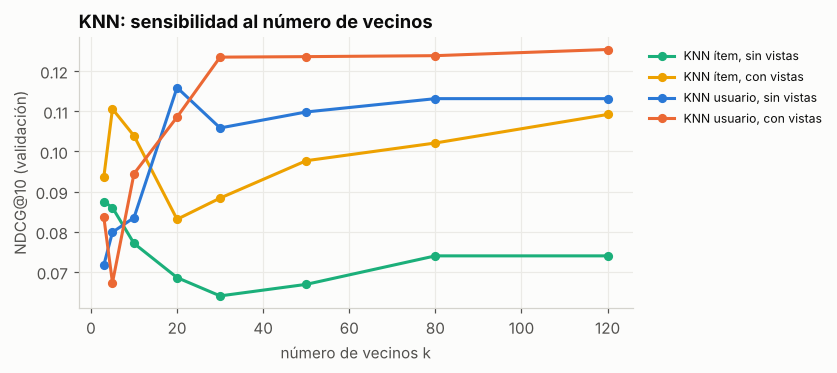

In [ ]:
filas = []
for var in ["usuario", "item"]:
    for vis in [False, True]:
        for k in [3, 5, 10, 20, 30, 50, 80, 120]:
            m = rr.KNNColaborativo(k=k, variante=var, usar_vistas=vis).fit(val)
            r = rr.evaluar(m, val).loc[10]
            filas.append({"variante": var, "usar_vistas": vis, "k": k, **r[["ndcg", "hit_rate", "cobertura"]]})
grid_knn = pd.DataFrame(filas)
grid_knn.to_csv(RES / "grid_knn.csv", index=False)
display(grid_knn.sort_values("ndcg", ascending=False).head(8).round(3))
mejor_knn_u = elegir(grid_knn[grid_knn.variante == 'usuario'], ['k', 'usar_vistas'])
mejor_knn_i = elegir(grid_knn[grid_knn.variante == 'item'], ['k', 'usar_vistas'])
print('Elegidos (parsimonia):'); display(pd.DataFrame([mejor_knn_u, mejor_knn_i]).round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
cols = {("usuario", False): AZUL, ("usuario", True): NARANJA, ("item", False): AQUA, ("item", True): AMARILLO}
for (var, vis), g in grid_knn.groupby(["variante", "usar_vistas"]):
    ax.plot(g.k, g.ndcg, marker="o", lw=2, ms=5, color=cols[(var, vis)],
            label=f"KNN {'ítem' if var == 'item' else 'usuario'}, {'con' if vis else 'sin'} vistas")
ax.set_xlabel("número de vecinos k"); ax.set_ylabel("NDCG@10 (validación)")
ax.set_title("KNN: sensibilidad al número de vecinos"); ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
guardar(fig, "13_ajuste_knn"); plt.show()

**Interpretación.** Ninguna variante de KNN supera a la popularidad en validación.
- **KNN usuario:** mejora al aumentar *k* hasta unos 20-30 vecinos y luego se estabiliza (con vistas llega a 0.125). Con pocos vecinos, la estimación depende de 3 a 10 estudiantes y es muy inestable. Por la regla de parsimonia se elige **k = 20, sin vistas** (0.116).
- **KNN ítem:** funciona mejor con muy pocos vecinos (**k = 5, con vistas**: 0.111). Al agregar más vecinos se suman cursos poco relacionados que diluyen la señal.

La causa principal es la **dispersión de 93.8 %**: con unas 4 inscripciones por estudiante en entrenamiento, dos estudiantes comparten pocos cursos y las similitudes del coseno se calculan sobre muy pocas coincidencias. A cambio, KNN ítem es el modelo que más recorre el catálogo (cobertura de 99 %).

## 3. Algoritmo de innovación: LightFM híbrido

**Por qué es innovador para este curso:** LightFM no fue desarrollado en clase. Combina en un solo modelo la factorización matricial (colaborativo) con los atributos de usuarios y cursos (contenido), por lo que también resuelve el *cold start*.

- **Principio (Kula, 2015):** cada usuario y cada curso se representan como la **suma de los embeddings de sus atributos**:
  $$\mathbf{q}_u = \sum_{f \in F_u} \mathbf{e}^U_f, \qquad \mathbf{p}_i = \sum_{g \in F_i} \mathbf{e}^I_g, \qquad \hat r_{ui} = \mathbf{q}_u \cdot \mathbf{p}_i + b_u + b_i$$
  Si un estudiante es nuevo, igual tiene atributos (carrera, nivel, objetivo, intereses), así que se le puede calcular $\mathbf{q}_u$.
- **Pérdida de ranking:**
  - **WARP** (*Weighted Approximate-Rank Pairwise*): por cada positivo muestrea negativos hasta encontrar uno mal ordenado y actualiza con más fuerza cuando el positivo estaba muy abajo en el ranking. Optimiza directamente la parte alta de la lista (ideal para Top-N).
  - **BPR** (*Bayesian Personalized Ranking*): maximiza la probabilidad de que un positivo tenga mayor puntaje que un negativo aleatorio.
- **Atributos de usuario:** carrera, nivel, idioma, objetivo laboral, tramo de ciclo, intereses y categorías que domina.
- **Atributos de curso:** categoría, dificultad, idioma, plataforma, tipo y duración (corta/media/larga).
- **Datos de entrada:** inscripciones de entrenamiento con peso implícito (inscripción 3, finalización 4) como `sample_weight`.
- **Hiperparámetros ajustados:** pérdida (WARP/BPR), dimensión de los embeddings (`no_components`) y número de épocas. Cada configuración se entrena con **3 semillas** y se promedia, porque el entrenamiento es estocástico.
- **Limitaciones:** más hiperparámetros, entrenamiento estocástico, menor interpretabilidad que KNN y dependencia de una librería que requiere compilación (en la app se usan los embeddings exportados con numpy).

In [ ]:
print(inspect.getsource(rr.LightFMHibrido.fit))

    def fit(self, datos: Particion):
        from lightfm import LightFM
        from lightfm.data import Dataset
        self.datos = datos
        ds = Dataset()
        uf = datos.usuarios.apply(atributos_usuario, axis=1)
        itf = datos.cursos.apply(atributos_curso, axis=1)
        ds.fit(users=datos.usuarios.user_id, items=datos.cursos.course_id,
               user_features=sorted({x for l in uf for x in l}) if self.usar_atributos else None,
               item_features=sorted({x for l in itf for x in l}) if self.usar_atributos else None)
        pos = datos.train[datos.train.positivo == 1]
        w = pos["peso"].astype(float).values if self.usar_peso else np.ones(len(pos))
        inter, pesos = ds.build_interactions(zip(pos.user_id, pos.course_id, w))
        self.ds = ds
        if self.usar_atributos:
            self.UF = ds.build_user_features(zip(datos.usuarios.user_id, uf))
            self.IF = ds.build_item_features(zip(datos.cursos.course_id, itf))
        else:
 

144 entrenamientos en 92 s


,loss,no_components,epochs,ndcg,ndcg_sd,hit_rate,cobertura
23,warp,128,200,0.209,0.002,0.414,0.819
22,warp,128,150,0.200,0.006,0.378,0.785
17,warp,64,200,0.200,0.002,0.383,0.726
21,warp,128,100,0.199,0.005,0.366,0.707
16,warp,64,150,0.193,0.003,0.376,0.673
10,warp,32,150,0.189,0.009,0.366,0.642
15,warp,64,100,0.188,0.008,0.373,0.636
11,warp,32,200,0.186,0.008,0.356,0.660


Elegido (parsimonia):
loss                 warp
no_components          64
epochs                200
ndcg             0.200019
ndcg_sd          0.001836
hit_rate         0.383459
cobertura        0.725857


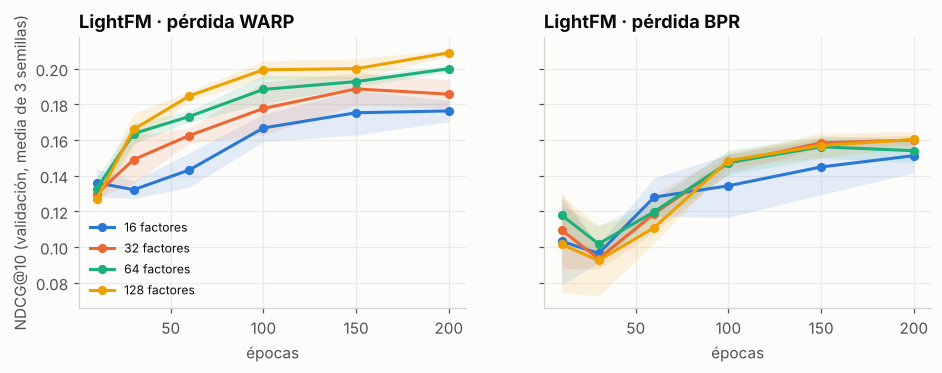

In [ ]:
t0 = time.time(); filas = []
for loss in ["warp", "bpr"]:
    for comp in [16, 32, 64, 128]:
        for ep in [10, 30, 60, 100, 150, 200]:
            rs = [rr.evaluar(rr.LightFMHibrido(no_components=comp, loss=loss, epochs=ep, seed=s).fit(val), val).loc[10]
                  for s in (42, 43, 44)]
            r = pd.concat(rs, axis=1).T
            filas.append({"loss": loss, "no_components": comp, "epochs": ep, "ndcg": r.ndcg.mean(), "ndcg_sd": r.ndcg.std(),
                          "hit_rate": r.hit_rate.mean(), "cobertura": r.cobertura.mean()})
grid_lfm = pd.DataFrame(filas)
grid_lfm.to_csv(RES / "grid_lightfm.csv", index=False)
print(f"{len(grid_lfm) * 3} entrenamientos en {time.time() - t0:.0f} s")
display(grid_lfm.sort_values("ndcg", ascending=False).head(8).round(3))
mejor_lfm = elegir(grid_lfm, ['no_components', 'epochs', 'loss'])
print('Elegido (parsimonia):'); print(mejor_lfm.to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, loss in zip(axes, ["warp", "bpr"]):
    for comp, c in zip([16, 32, 64, 128], [AZUL, NARANJA, AQUA, AMARILLO]):
        g = grid_lfm[(grid_lfm.loss == loss) & (grid_lfm.no_components == comp)]
        ax.plot(g.epochs, g.ndcg, marker="o", lw=2, ms=5, color=c, label=f"{comp} factores")
        ax.fill_between(g.epochs, g.ndcg - g.ndcg_sd, g.ndcg + g.ndcg_sd, color=c, alpha=0.12, lw=0)
    ax.set_title(f"LightFM · pérdida {loss.upper()}"); ax.set_xlabel("épocas")
axes[0].set_ylabel("NDCG@10 (validación, media de 3 semillas)"); axes[0].legend(frameon=False, fontsize=8)
guardar(fig, "14_ajuste_lightfm"); plt.show()

In [ ]:
# Ablación: ¿cuánto aportan los atributos? (misma configuración, sin atributos = factorización pura)
cfg = dict(no_components=int(mejor_lfm.no_components), loss=mejor_lfm.loss, epochs=int(mejor_lfm.epochs))
abl = {}
for nombre, usar in [("con atributos (híbrido)", True), ("sin atributos (solo colaborativo)", False)]:
    rs = [rr.evaluar(rr.LightFMHibrido(**cfg, usar_atributos=usar, seed=s).fit(val), val).loc[10] for s in (42, 43, 44)]
    abl[nombre] = pd.concat(rs, axis=1).T.mean()
pd.DataFrame(abl).T[["ndcg", "hit_rate", "precision", "cobertura"]].round(3)

,ndcg,hit_rate,precision,cobertura
con atributos (híbrido),0.200,0.383,0.038,0.726
sin atributos (solo colaborativo),0.082,0.175,0.018,0.900


**Interpretación.**
- **Pérdida:** **WARP** supera a BPR en todas las configuraciones. Era lo esperable, porque WARP optimiza directamente la parte alta del ranking, que es justo lo que miden las métricas @K.
- **Factores y épocas:** con WARP, el NDCG@10 mejora con más factores y más épocas, y se estabiliza alrededor de 0.20 desde unas 100-150 épocas.
- **Configuración elegida:** la regla de parsimonia elige **WARP, 64 factores, 200 épocas** (NDCG@10 = 0.200 ± 0.002 entre semillas). La de 128 factores obtiene 0.209, una diferencia dentro de la tolerancia que no justifica el doble de parámetros. La desviación entre semillas es pequeña, así que el resultado es estable.
- **Ablación:** al quitar los atributos y dejar solo la factorización colaborativa, el NDCG@10 cae de 0.200 a 0.082 (peor que la popularidad).

Esto confirma que el aporte de LightFM viene de **combinar interacciones con atributos de estudiantes y cursos**. Hay que reconocer en la sustentación que esos mismos atributos guían la simulación de los datos, por lo que la ventaja del modelo híbrido puede estar sobreestimada respecto a datos reales.

## 4. Resumen del ajuste en validación

precision  recall  hit_rate   ndcg  cobertura
K  modelo                                                           
5  Popularidad             0.030   0.150     0.150  0.101      0.103
   Contenido (TF-IDF)      0.033   0.165     0.165  0.105      0.617
   KNN usuario             0.026   0.124     0.128  0.073      0.579
   KNN ítem                0.029   0.139     0.143  0.079      0.963
   LightFM híbrido         0.051   0.252     0.256  0.160      0.579
10 Popularidad             0.023   0.233     0.233  0.128      0.168
   Contenido (TF-IDF)      0.029   0.282     0.286  0.143      0.869
   KNN usuario             0.026   0.259     0.263  0.116      0.794
   KNN ítem                0.024   0.237     0.241  0.111      0.991
   LightFM híbrido         0.038   0.372     0.376  0.198      0.710

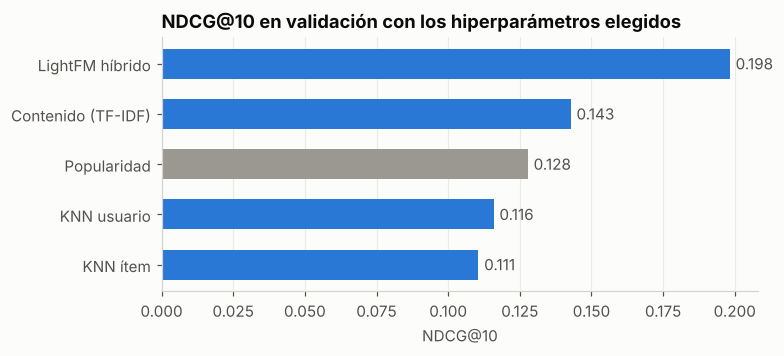

In [ ]:
modelos_val = {
    "Popularidad": rr.Popularidad(),
    "Contenido (TF-IDF)": rr.ContenidoTFIDF(ngram=eval(mejor_cont.ngram), alpha_perfil=float(mejor_cont.alpha_perfil),
                                            usar_vistas=bool(mejor_cont.usar_vistas)),
    "KNN usuario": rr.KNNColaborativo(k=int(mejor_knn_u.k), variante="usuario", usar_vistas=bool(mejor_knn_u.usar_vistas)),
    "KNN ítem": rr.KNNColaborativo(k=int(mejor_knn_i.k), variante="item", usar_vistas=bool(mejor_knn_i.usar_vistas)),
    "LightFM híbrido": rr.LightFMHibrido(**cfg),
}
res_val = {n: rr.evaluar(m.fit(val), val) for n, m in modelos_val.items()}
tabla = pd.concat({k: rr.tabla_metricas(res_val, k) for k in (5, 10)}, names=["K", "modelo"]).drop(columns="usuarios")
display(tabla.round(3))

t10 = rr.tabla_metricas(res_val, 10).sort_values("ndcg")
fig, ax = plt.subplots(figsize=(7, 3))
cols = [GRIS if n == "Popularidad" else AZUL for n in t10.index]
ax.barh(t10.index, t10.ndcg, color=cols, height=0.6)
for y, v in enumerate(t10.ndcg): ax.text(v + 0.002, y, f"{v:.3f}", va="center", color=TXT2)
ax.set_title("NDCG@10 en validación con los hiperparámetros elegidos"); ax.set_xlabel("NDCG@10"); ax.grid(axis="y", visible=False)
guardar(fig, "15_resumen_validacion"); plt.show()

In [ ]:
hiper = {
    "criterio": "NDCG@10 en validación (partición temporal por usuario), regla de parsimonia con tolerancia 0.01",
    "Contenido (TF-IDF)": {"ngram": list(eval(mejor_cont.ngram)), "alpha_perfil": float(mejor_cont.alpha_perfil),
                           "usar_vistas": bool(mejor_cont.usar_vistas)},
    "KNN usuario": {"k": modelos_val["KNN usuario"].k, "variante": "usuario", "usar_vistas": modelos_val["KNN usuario"].usar_vistas},
    "KNN ítem": {"k": modelos_val["KNN ítem"].k, "variante": "item", "usar_vistas": modelos_val["KNN ítem"].usar_vistas},
    "LightFM híbrido": cfg,
}
(RES / "hiperparametros.json").write_text(json.dumps(hiper, indent=2, ensure_ascii=False))
tabla.round(4).to_csv(RES / "metricas_validacion.csv")
print(json.dumps(hiper, indent=2, ensure_ascii=False))

{
  "criterio": "NDCG@10 en validación (partición temporal por usuario), regla de parsimonia con tolerancia 0.01",
  "Contenido (TF-IDF)": {
    "ngram": [
      1,
      1
    ],
    "alpha_perfil": 0.9,
    "usar_vistas": false
  },
  "KNN usuario": {
    "k": 20,
    "variante": "usuario",
    "usar_vistas": false
  },
  "KNN ítem": {
    "k": 5,
    "variante": "item",
    "usar_vistas": true
  },
  "LightFM híbrido": {
    "no_components": 64,
    "loss": "warp",
    "epochs": 200
  }
}


**Interpretación.** En validación, el ranking por NDCG@10 es: **LightFM híbrido (0.198) > Contenido TF-IDF (0.143) > Popularidad (0.128) > KNN usuario (0.116) > KNN ítem (0.111)**. Solo los dos modelos que usan información del perfil y del curso superan al baseline. Los dos colaborativos puros quedan por debajo, por la dispersión de la matriz.

La Precision@K es baja en todos los modelos por construcción: cada estudiante tiene una sola inscripción a predecir, así que el máximo posible es 1/K (0.20 con K = 5 y 0.10 con K = 10). Por eso se prioriza NDCG y Hit Rate.

Estos valores sirven solo para elegir hiperparámetros. La comparación definitiva se hace en el notebook 03, sobre el conjunto de prueba, reentrenando con entrenamiento + validación. Los hiperparámetros quedaron guardados en `resultados/hiperparametros.json`.

## 5. Estrategia para estudiantes nuevos (*cold start*)

Un estudiante que recién se registra no tiene historial, así que KNN y el contenido por historial no pueden usarse. Se comparan tres estrategias que solo usan el **formulario de registro** (carrera, ciclo, nivel, idioma, objetivo laboral e intereses):

1. **Popularidad filtrada (reglas):** cursos populares, solo en español si el estudiante no lee inglés y sin cursos más de un nivel por encima del suyo.
2. **Contenido por perfil declarado:** TF-IDF del texto del objetivo laboral + intereses contra el texto de cada curso.
3. **LightFM solo con atributos:** se construye $\mathbf{q}_u$ sumando los embeddings de los atributos del formulario.
4. **LightFM solo con atributos + reglas:** la estrategia 3 con las mismas reglas de idioma y nivel de la estrategia 1.

**Evaluación simulada:** a los 133 estudiantes de validación se les "borra" el historial y se les recomienda solo con su perfil. Se mide si aciertan su inscripción de validación.

In [ ]:
class SoloPerfil:
    # Envoltorio: ignora el historial y puntúa con el perfil declarado del estudiante
    def __init__(self, nombre, fn): self.nombre, self.fn = nombre, fn
    def puntajes(self, user_id):
        return self.fn(usuarios.set_index("user_id").loc[user_id].to_dict())

lfm_cs = rr.LightFMHibrido(**cfg).fit(val)
cont_cs = rr.ContenidoTFIDF(ngram=eval(mejor_cont.ngram)).fit(val)
pop_s = rr.Popularidad().fit(val).puntajes(None)

cs = {"Popularidad sin filtrar": SoloPerfil("pop", lambda p: pop_s),
      "Popularidad filtrada (idioma y nivel)": SoloPerfil("popf", lambda p: rr.aplicar_reglas(pop_s, cursos, p)),
      "Contenido por perfil declarado": SoloPerfil("cont", cont_cs.puntajes_perfil),
      "LightFM solo con atributos": SoloPerfil("lfm", lfm_cs.puntajes_perfil),
      "LightFM solo con atributos + reglas": SoloPerfil("lfmr", lambda p: rr.aplicar_reglas(lfm_cs.puntajes_perfil(p), cursos, p))}
res_cs = {n: rr.evaluar(m, val) for n, m in cs.items()}
display(rr.tabla_metricas(res_cs, 10).drop(columns="usuarios").round(3))

,precision,recall,hit_rate,ndcg,cobertura
Popularidad sin filtrar,0.023,0.233,0.233,0.128,0.168
Popularidad filtrada (idioma y nivel),0.026,0.256,0.256,0.135,0.206
Contenido por perfil declarado,0.029,0.289,0.293,0.149,0.841
LightFM solo con atributos,0.038,0.380,0.383,0.203,0.673
LightFM solo con atributos + reglas,0.038,0.372,0.376,0.198,0.710


In [ ]:
# Demostración: estudiante nuevo
nuevo = {"carrera": "Estadística e Informática", "ciclo": 7, "nivel": "Básico", "idioma_preferido": "es",
         "objetivo_laboral": "Data Analyst", "intereses": "SQL y Bases de Datos; Power BI", "habilidades_actuales": "Estadística"}
demo = {}
for nombre, s in [("LightFM solo atributos", lfm_cs.puntajes_perfil(nuevo)),
                  ("LightFM + reglas", rr.aplicar_reglas(lfm_cs.puntajes_perfil(nuevo), cursos, nuevo))]:
    top = np.lexsort((np.arange(len(s)), -s))[:10]
    demo[nombre] = (cursos.iloc[top]["titulo"].str[:45] + " · " + cursos.iloc[top]["dificultad"]).values
pd.DataFrame(demo, index=range(1, 11))

,LightFM solo atributos,LightFM + reglas
1,Introducción a SQL · Básico,Introducción a SQL · Básico
2,Excel avanzado: importación y análisis de dat ...,Introducción a Power BI · Básico
3,Introducción a Power BI · Básico,Curso de Excel Intermedio · Intermedio
4,Curso de Excel Intermedio · Intermedio,Curso de PostgreSQL Aplicado a Ciencia de Dat ...
5,Curso de PostgreSQL Aplicado a Ciencia de Dat ...,Curso de Excel Básico · Básico
6,Curso de Excel Avanzado para Análisis de Dato ...,Introducción a R · Básico
7,Curso de Excel Básico · Básico,Excel: gestión de datos · Intermedio
8,Introducción a R · Básico,Curso de Tableau: Visualización de Datos y St ...
9,Excel: gestión de datos · Intermedio,Curso de Matemáticas para Data Science: Proba ...
10,Curso de Tableau: Visualización de Datos y St ...,Curso de Power BI · Básico


**Interpretación.** Sin ningún historial, **LightFM con solo atributos** alcanza un NDCG@10 de 0.203 y acierta la siguiente inscripción en el 38 % de los casos. Es casi lo mismo que el modelo completo con historial (0.198), y bastante más que la popularidad (0.128) o el contenido por perfil declarado (0.149). Que el historial individual aporte tan poco es una señal de lo que ya advertimos: en los datos simulados, el perfil explica la mayor parte de las elecciones.

Las **reglas de negocio** casi no cambian la precisión (0.198 frente a 0.203). Sin embargo, garantizan dos cosas que un estudiante notaría de inmediato:
- no se le muestran cursos en inglés si no lee inglés;
- no se le recomienda saltar dos niveles.

En el ejemplo, un estudiante de nivel básico que apunta a Data Analyst ya no recibe los dos cursos de Excel avanzado.

**Estrategia adoptada para estudiantes nuevos:** LightFM con atributos del formulario + reglas de idioma y nivel. Si el modelo no estuviera disponible, se usa como respaldo la popularidad filtrada por las mismas reglas.

## 6. Conclusiones del modelamiento

1. **Cuatro recomendadores implementados** sobre la misma partición temporal y con la misma regla de exclusión de cursos ya tomados: baseline de popularidad, contenido TF-IDF, KNN (usuario e ítem) y LightFM híbrido. Son tres familias distintas: contenido, colaborativo e híbrido de factorización.
2. **Hiperparámetros elegidos** con NDCG@10 en validación y una regla de parsimonia:
   - Contenido: $\alpha = 0.9$, unigramas.
   - KNN usuario: *k* = 20.
   - KNN ítem: *k* = 5 con vistas.
   - LightFM: WARP, 64 factores, 200 épocas.
3. **LightFM** es el mejor en validación (NDCG@10 ≈ 0.20, un 55 % más que la popularidad) y además resuelve el *cold start* con los atributos del formulario.
4. **Los modelos colaborativos puros** (KNN y LightFM sin atributos) no superan a la popularidad, por la dispersión de la matriz.
5. **Advertencia metodológica:** la ventaja de los modelos que usan atributos es coherente con cómo se generaron los datos. Debe discutirse como limitación y no como prueba de que funcionarían igual con estudiantes reales.
6. **Pendiente para el notebook 03:**
   - comparación final en prueba (K = 5 y 10);
   - prueba de robustez con el corte global;
   - análisis por tipo de estudiante;
   - selección argumentada considerando desempeño, costo y utilidad.